In [1]:
import numpy as np
import matplotlib.pyplot as plt
from simulator_unobserved import (
    marker_dict,
    location_dict,
    location_colors_dict,
)

from trafficking_inference.CellVADIS import (
    Stitch_OT,
    groundtruth_check,
    simulate_data,
    Joint_OT,
)
from trafficking_inference.helper_functions import (
    get_true_fate_probabilities,
    avg_thresholded_accuracy,
    get_predicted_location_fractions_thresholded,
)


figure_path = "simulator_unobserved/figures/"
data_path = "data/"
plt.style.use("default")

plt.style.use("default")

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial"],
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "legend.fontsize": 6,
        "legend.frameon": False,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.figsize": (3.5, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": "standard",
        # "savefig.pad_inches": 0.02,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)

cm = 1 / 2.54  # centimeters in inches
dt = 0.02

In [2]:
# model params
n_hills_transition = 3  # Hill coefficient for all trafficking transitions
params = {
    "n_cells": 60000,  # Number of cells to simulate
    "dt": 0.02,  # Time step (hours)
    "p_cd44_base": 5,  # Base CD44 expression rate
    "cd44_base_multiplier_sd": 0.4,  # SD for CD44 base rate multiplier
    "cd44_base_rate_multiplier_weight": 0.5,  # Weight for the base rate multiplier in CD44 expression
    "d_cd44_base": 0.1,  # CD44 degradation rate
    "p_cxcr4_base": 6,  # CXCR4 expression rate
    "cxcr4_base_multiplier_sd": 0.1,  # SD for CXCR4 base rate multiplier
    "cxcr4_base_rate_multiplier_weight": 0.2,  # Weight for the base rate multiplier in CXCR4 expression
    "d_cxcr4_base": 0.1,  # CXCR4 degradation rate
    "d_2_cxcr4": 0.5,  # Additional degradation rate for CXCR4 when in bone marrow
    "K_dwell_time_cxcr4": 16,  # Half-saturation constant for dwell time effect on CXCR4
    "n_hill_dwell_time_cxcr4": 4,  # Hill coefficient for dwell time effect on CXCR4
    "p_s1pr1_base": 12,  # S1PR1 expression rate
    "d_s1pr1_base": 0.1,  # S1PR1 degradation rate
    "s1pr1_base_multiplier_sd": 0.1,  # SD for S1PR1 base rate multiplier
    "d_2_s1pr1": 1,  # Additional degradation rate for S1PR1 when in blood
    "K_CD69_S1PR1": 60,  # Half-saturation constant for CD69 in the S1PR1 degradation
    "n_hill_cd69_s1pr1": 6,  # Hill coefficient for CD69 effect on S1PR1 degradation
    "K_dwell_time_s1pr1": 0.05,  # Half-saturation constant for dwell time effect on S1PR1
    "n_hill_dwell_time_s1pr1": 4,  # Hill coefficient for dwell time effect on S1PR1
    "p_ccr7_base": 8,  # CCR7 expression rate
    "ccr7_base_multiplier_sd": 0.1,  # SD for CCR7 base rate multiplier
    "ccr7_base_rate_multiplier_weight": 0.3,  # Weight for the base rate multiplier in CCR7 expression
    "d_ccr7_base": 0.1,  # CCR7 degradation rate
    "d_2_ccr7": 1,  # Additional degradation rate for CCR7 when in LN
    "K_dwell_time_ccr7": 8,  # Half-saturation constant for dwell time effect on CCR7
    "n_hill_dwell_time_ccr7": 4,  # Hill coefficient for dwell time effect on CCR7
    "p_cd69_base": 3,  # CD69 expression rate
    "d_cd69_base": 0.1,  # CD69 degradation rate
    "p_cd69_base_multiplier_sd": 0.5,  # SD for CD69 multiplier
    "cd69_base_rate_multiplier_weight": 0.8,  # Weight for the base rate multiplier in CD69 expression
    "p_cd62l_base": 8,  # CD62L expression rate
    "d_cd62l_base": 0.1,  # CD62L degradation rate
    "p_cd62l_base_multiplier_sd": 0.3,  # SD for CD62L multiplier
    "cd62l_base_rate_multiplier_weight": 0.7,  # Weight for the base rate multiplier in CD62L expression
    "p_a4b7_base": 4,  # a4b7 expression rate
    "d_a4b7_base": 0.1,  # a4b7 degradation rate
    "p_a4b7_base_multiplier_sd": 0.5,  # SD for a4b7 multiplier
    "a4b7_base_rate_multiplier_weight": 0.5,  # Weight for the base rate multiplier in a4b7 expression
    "p_Lambda_base": 4,  # Lambda expression rate
    "d_Lambda_base": 0.1,  # Lambda
    "K_Lambda_blood_to_U": 50,  # Half-saturation constant for Lambda in the transition
    "Lambda_base_rate_multiplier_weight": 0.5,  # Weight for the base rate multiplier in Lambda expression
    "K_Lambda_blood_to_xx": 50,  # Half-saturation constant for Lambda in the transition
    "Lambda_steepness": 1.0,
    "blood_to_ln_rate": 30 * 1,  # Rate of transition from blood to lymph nodes
    "K_CCR7_blood_to_ln": 100,  # Half-saturation constant for CCR7 in the transition
    "K_CD62L_blood_to_ln": 130,  # Half-saturation constant for CD62L in the transition
    "n_hill_CCR7_blood_to_ln": n_hills_transition,  # Hill coefficient for CCR7 in blood to LN transition
    "n_hill_CD62L_blood_to_ln": n_hills_transition,  # Hill coefficient for CD62L in blood to LN transition
    "ln_to_blood_rate": 0.07,  # Rate of transition from lymph nodes to blood
    "K_S1PR1_ln_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "K_CCR7_ln_to_blood": 70,  # Half-saturation constant for CCR7 in the transition
    "n_hill_S1PR1_ln_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in LN to blood transition
    "n_hill_CCR7_ln_to_blood": n_hills_transition,  # Hill coefficient for CCR7 in LN to blood transition
    "spleen_to_blood_rate": 1.5,  # Rate of transition from spleen to blood
    "K_S1PR1_spleen_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_spleen_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in spleen to blood transition
    "blood_to_spleen_rate": 30 * 0.5,  # Rate of transition from blood to spleen
    "K_CCR7_blood_to_spleen": 100,  # Half-saturation constant for CCR7 in the transition
    "n_hill_CCR7_blood_to_spleen": n_hills_transition,  # Hill coefficient for CCR7 in blood to spleen transition
    "BM_to_blood_rate": 0.04,  # Rate of transition from bone marrow to blood
    "K_S1PR1_BM_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "K_CXCR4_BM_to_blood": 120,  # Half-saturation constant for CXCR4 in the transition
    "n_hill_S1PR1_BM_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in BM to blood transition
    "n_hill_CD44_BM_to_blood": n_hills_transition,  # Hill coefficient for CD44 in BM to blood transition
    "n_hill_CXCR4_BM_to_blood": n_hills_transition,  # Hill coefficient for CXCR4 in BM to blood transition
    "K_CD44_BM_to_blood": 100,  # Half-saturation constant for CD44 in the transition
    "blood_to_BM_rate": 30 * 0.3,  # Rate of transition from blood to bone marrow
    "K_CXCR4_blood_to_BM": 120,  # Half-saturation constant for CXCR4 in the transition
    "n_hill_CXCR4_blood_to_BM": n_hills_transition,  # Hill coefficient for CXCR4 in blood to BM transition
    "K_CD44_blood_to_BM": 90,  # Half-saturation constant for CD44 in the transition
    "n_hill_CD44_blood_to_BM": 2,  # Hill coefficient for CD44 in blood to BM transition
    "gut_to_blood_rate": 0.2,  # Rate of transition from gut to blood
    "K_S1PR1_gut_to_blood": 60,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_gut_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in gut to blood transition
    "blood_to_gut_rate": 30 * 0.2,  # Rate of transition from blood to gut
    "K_a4b7_blood_to_gut": 80,  # Half-saturation constant for a4b7 in the transition
    "n_hill_a4b7_blood_to_gut": n_hills_transition,  # Hill coefficient for a4b7 in blood to gut transition
    "K_S1PR1_blood_to_xx": 40,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_blood_to_xx": n_hills_transition,  # Hill coefficient for S1PR1 in blood to xx transition
    "blood_to_U_rate": 30 * 0.2,  # Rate of transition from blood to unobserved
    "n_hill_Lambda_blood_to_U": 6,  # Hill coefficient for Lambda in blood to unobserved transition
    "U_to_blood_rate": 0.2,  # Rate of transition from unobserved to blood
    "K_S1PR1_blood_to_U": 40,  # Half-saturation constant for S1PR1 in the transition
    "K_S1PR1_U_to_blood": 40,  # Half-saturation constant for S1PR1 in the transition
    "n_hill_S1PR1_U_to_blood": n_hills_transition,  # Hill coefficient for S1PR1 in unobserved to blood transition
}

In [3]:
use_stored_data = False
if use_stored_data:
    # Load simulation results
    true_next_locations_raw = np.load(data_path + "simulated_true_next_locations.npy")
    locations = np.load(data_path + "simulated_locations.npy")
    data_raw = np.load(data_path + "simulated_data_raw.npy")
    data_normalized = np.load(data_path + "simulated_data_normalized.npy")
else:
    data_raw, data_normalized, locations, true_next_locations_raw = simulate_data(
        params, procs=8, store_raw=False, with_unobserved=True
    )

color_map = location_colors_dict

true_next_locations = true_next_locations_raw[
    locations == 2
]  # only consider cells starting in blood
real_fractions = np.zeros(len(location_dict.keys()))
for j, loc in enumerate([1, 3, 4, 5, 6]):  # LN, Spleen, BM, Gut, U
    real_fractions[j] = np.sum(true_next_locations == loc) / len(true_next_locations)

print("Real fractions for cells starting in blood:")
print(f"Blood to LN: {real_fractions[0]:.3f}")
print(f"Blood to spleen: {real_fractions[1]:.3f}")
print(f"Blood to BM: {real_fractions[2]:.3f}")
print(f"Blood to gut: {real_fractions[3]:.3f}")
print(f"Blood to U: {real_fractions[4]:.3f}")

print("#Cells per location currently:")
for j, loc in enumerate([1, 2, 3, 4, 5, 6]):
    print(f"{location_dict[loc]}: {np.sum(locations == loc)}")

Real fractions for cells starting in blood:
Blood to LN: 0.130
Blood to spleen: 0.205
Blood to BM: 0.032
Blood to gut: 0.110
Blood to U: 0.523
#Cells per location currently:
LN: 9361
Blood: 3326
Spleen: 3888
BM: 11011
Gut: 6282
U: 25951


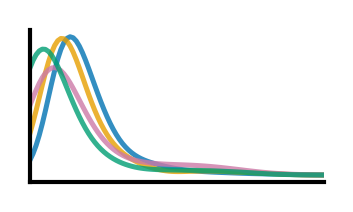

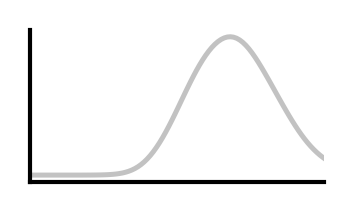

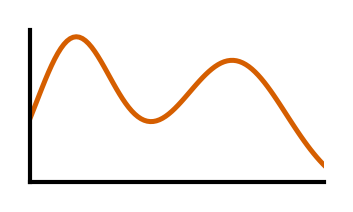

In [4]:
from scipy import stats

# insted of histograms do kde line plots
plt.figure(figsize=(2.7, 1.5, "cm"), layout="constrained")
for j, loc in enumerate([1, 3, 4, 5]):  # LN, Spleen, BM, Gut, U
    kde = stats.gaussian_kde(
        data_raw[locations == loc, marker_dict["Lambda"]], bw_method=0.4
    )
    x = np.linspace(-5, 130, 100)
    plt.plot(
        x,
        kde(x + j * 4),
        color=color_map[loc],
        label=location_dict[loc],
        alpha=0.8,
        linewidth=1.2,
    )
# no xticks, no yticks
plt.xticks([])
plt.yticks([])
plt.xlim(-5, 125)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
# SET OTHER SPLINES TO 1.2
plt.gca().spines["bottom"].set_linewidth(1)
plt.gca().spines["left"].set_linewidth(1)
# add arrow to botom spine to indicate x axis
plt.savefig(figure_path + "Lambda_kde_per_location.pdf")
plt.show()

# same but only for compartment 6 this time
plt.figure(figsize=(2.7, 1.5, "cm"), layout="constrained")
kde = stats.gaussian_kde(data_raw[locations == 6, marker_dict["Lambda"]], bw_method=0.4)
x = np.linspace(-5, 130, 100)
plt.plot(
    x, kde(x), color=color_map[6], label=location_dict[6], alpha=0.8, linewidth=1.2
)
plt.xticks([])
plt.yticks([])
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["left"].set_linewidth(1)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_linewidth(1)
plt.xlim(-5, 125)
plt.savefig(figure_path + "Lambda_kde_per_location_U.pdf")
plt.show()

# same but for blood
plt.figure(figsize=(2.7, 1.5, "cm"), layout="constrained")
kde = stats.gaussian_kde(data_raw[locations == 2, marker_dict["Lambda"]], bw_method=0.4)
x = np.linspace(-5, 130, 100)
plt.plot(x, kde(x), color=color_map[2], label=location_dict[2], linewidth=1.2)
plt.xticks([])
plt.yticks([])
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_linewidth(1)
plt.gca().spines["bottom"].set_linewidth(1)
plt.xlim(-5, 125)
plt.savefig(figure_path + "Lambda_kde_per_location_Blood.pdf")
plt.show()

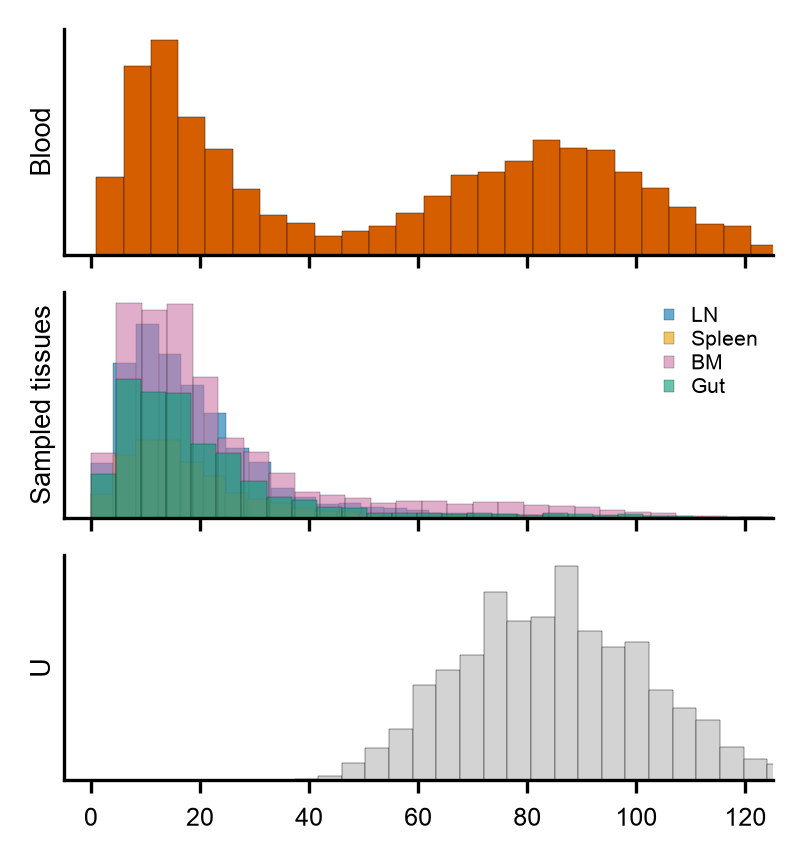

In [5]:
# also do histograms for Lambda in tissues (Blood, Sampled tissues and U)
fig, ax = plt.subplots(3, 1, figsize=(6.5, 7, "cm"), layout="constrained", sharex=True)
# for blood
ax[0].hist(
    data_raw[locations == 2, marker_dict["Lambda"]],
    bins=30,
    color="#D55E00",
    edgecolor="black",
    linewidth=0.1,
)
ax[0].set_yticks([])
ax[0].spines["top"].set_visible(False)
ax[0].spines["right"].set_visible(False)
ax[0].spines["left"].set_linewidth(0.8)
ax[0].spines["bottom"].set_linewidth(0.8)
ax[0].set_xlim(-5, 125)
# set ylabel to Blood
ax[0].set_ylabel("Blood", rotation=90, labelpad=5, fontsize=6.5, va="center")


# for sampled tissues do overlapping histograms with lwoer alpha
for j, loc in enumerate([1, 3, 4, 5]):  # LN, Spleen, BM, Gut
    ax[1].hist(
        data_raw[locations == loc, marker_dict["Lambda"]],
        bins=30,
        color=color_map[loc],
        edgecolor="black",
        linewidth=0.1,
        alpha=0.6,
        label=location_dict[loc],
    )
ax[1].set_yticks([])
ax[1].spines["top"].set_visible(False)
ax[1].spines["right"].set_visible(False)
ax[1].spines["left"].set_linewidth(0.8)
ax[1].spines["bottom"].set_linewidth(0.8)
ax[1].set_xlim(-5, 125)
ax[1].set_ylabel("Sampled tissues", rotation=90, labelpad=5, fontsize=6.5, va="center")
ax[1].legend(
    loc="upper right",
    fontsize=5,
    frameon=False,
    handlelength=0.5,
    handleheight=0.5,
    labelspacing=0.2,
    borderpad=0.2,
)

# for unobserved
ax[2].hist(
    data_raw[locations == 6, marker_dict["Lambda"]],
    bins=30,
    color="lightgrey",
    edgecolor="black",
    linewidth=0.1,
)
ax[2].set_yticks([])
ax[2].spines["top"].set_visible(False)
ax[2].spines["right"].set_visible(False)
ax[2].spines["left"].set_linewidth(0.8)
ax[2].spines["bottom"].set_linewidth(0.8)
ax[2].set_xlim(-5, 125)
ax[2].set_ylabel("U", rotation=90, labelpad=5, fontsize=6.5, va="center")

plt.savefig(figure_path + "Lambda_hist_per_location.pdf")

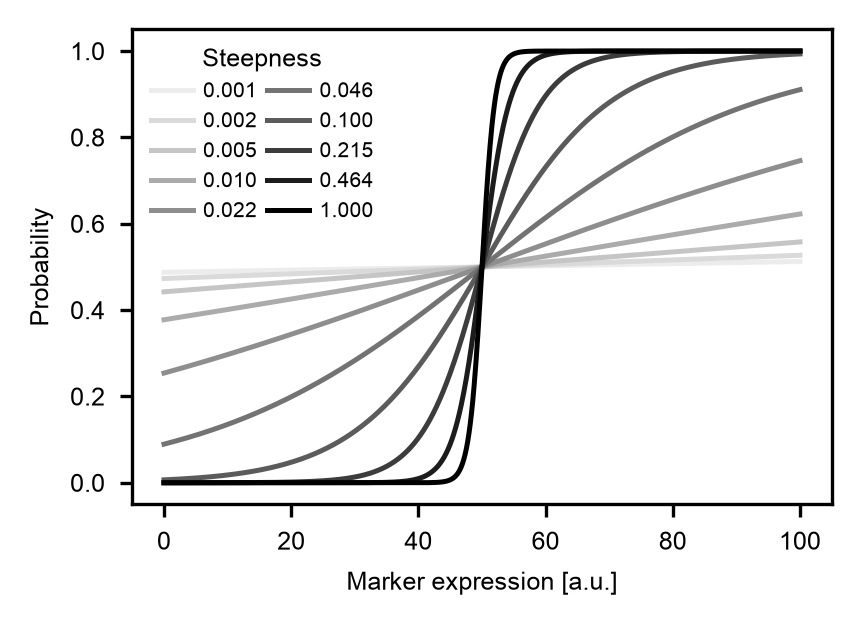

In [6]:
def sigmoid_function(x, K, n):
    return 1 / (1 + np.exp(-n * (x - K)))


plt.figure(figsize=(7, 5, "cm"), layout="constrained")
x = np.linspace(0, 100, 1000)
K = 50
n = 10
n_values = np.logspace(-3, 0, 10)
# use greyscale for the lines, with the first line being black and the last line being light grey
colors = plt.cm.Greys(np.linspace(0.15, 1, len(n_values)))
for n in n_values:
    plt.plot(
        x,
        sigmoid_function(x, K, n),
        label=f"{n:.3f}",
        color=colors[n_values.tolist().index(n)],
    )
plt.xlabel("Marker expression [a.u.]")
plt.ylabel("Probability")
plt.legend(fontsize=5)
# legend in two columns, with numbers only displaying the first 3 values after .
plt.legend(
    fontsize=5,
    ncol=2,
    title="Steepness",
    title_fontsize=6,
    columnspacing=0.5,
    handletextpad=0.5,
)
plt.savefig(figure_path + "sigmoid_different_steepness.pdf")
plt.show()

# Method testing 

### Inference with U compartment

In [7]:
from trafficking_inference.CellVADIS import groundtruth_check_unobserved


data_source = data_normalized[locations == 2]  # only consider cells starting in blood
data_target = data_normalized[
    locations != 2
]  # only consider cells starting in non-blood locations
target_locations = locations[
    locations != 2
]  # only consider cells starting in non-blood locations
target_locations = np.array([location_dict[loc] for loc in target_locations])
source_name = "Blood"

target_names = ["LN", "Spleen", "BM", "Gut", "U"]
fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Stitch_OT(
    data_source,
    data_target,
    target_locations,
    target_names,
    tau_a=0.5,
    subsample_non_blood=True,
    assign_unsampled_probs=False,
)


data_source_raw = data_raw[locations == 2]  # only consider cells starting in blood
target_locations = target_locations[selected_target_mask]
fate_groups_ids = [1, 3, 4, 5, 6]  # LN, Spleen, BM, Gut

stats = groundtruth_check(
    fate_matrix,
    OT_plan,
    data_source_raw,
    target_locations,
    target_names,
    params,
    true_next_locations,
    fate_groups_ids,
    with_unobserved=True,
)
print(stats)


# compute stats
true_fate_probabilities = get_true_fate_probabilities(
    data_source_raw, params, with_unobserved=True
)
true_fate_probabilities = true_fate_probabilities / true_fate_probabilities.sum(
    axis=1, keepdims=True
)

avg_thres_acc_true = avg_thresholded_accuracy(
    true_fate_probabilities[
        true_next_locations != 6
    ],  # [true_next_locations[locations==2]!=2]
    true_next_locations[true_next_locations != 6],
    fate_groups_ids=fate_groups_ids,
)


avg_thres_acc_pred = avg_thresholded_accuracy(
    fate_matrix[true_next_locations != 6],  # [true_next_locations[locations==2]!=2]
    true_next_locations[true_next_locations != 6],
    fate_groups_ids=fate_groups_ids,
)
print(
    f"Accuracy for cells going to sampled locations (LN, Spleen, BM, Gut): {(avg_thres_acc_pred / avg_thres_acc_true):.3f}"
)


avg_thres_acc_true = avg_thresholded_accuracy(
    true_fate_probabilities,  # [true_next_locations[locations==2]!=2]
    true_next_locations,
    fate_groups_ids=fate_groups_ids,
)


avg_thres_acc_pred = avg_thresholded_accuracy(
    fate_matrix,  # [true_next_locations[locations==2]!=2]
    true_next_locations,
    fate_groups_ids=fate_groups_ids,
)

print(
    f"Global accuracy for all cells (including those going to U): {(avg_thres_acc_pred / avg_thres_acc_true):.3f}"
)

groundtruth_check_unobserved(
    fate_matrix, data_source_raw, params, true_next_locations, fate_groups_ids
)

[0.81629585 0.78270054 0.91565378 0.88728257 0.01701672 0.09419492
 0.08790361 0.05111245 0.21265873 0.08258109 0.11102398 0.07351162
 0.06975346 0.717804   0.19936646 0.08822399]
Accuracy for cells going to sampled locations (LN, Spleen, BM, Gut): 0.857
Global accuracy for all cells (including those going to U): 0.887


array([0.17012184, 0.02924463, 0.88728257, 0.08822399, 0.3023858 ,
       0.86140046, 0.07764043, 0.1667675 , 0.16901097, 0.06349298,
       0.12502055, 0.475708  ])

### Inference without U compartment

In [8]:
data_source = data_normalized[locations == 2]  # only consider cells starting in blood
data_target = data_normalized[
    (locations != 2) & (locations != 6)
]  # only consider cells starting in non-blood locations
target_locations = locations[
    (locations != 2) & (locations != 6)
]  # only consider cells starting in non-blood locations
target_locations = np.array([location_dict[loc] for loc in target_locations])
source_name = "Blood"

target_names = ["LN", "Spleen", "BM", "Gut"]
fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Stitch_OT(
    data_source,
    data_target,
    target_locations,
    target_names,
    tau_a=0.5,
    subsample_non_blood=True,
)


data_source_raw = data_raw[locations == 2]  # only consider cells starting in blood
target_locations = target_locations[selected_target_mask]
fate_groups_ids = [1, 3, 4, 5]  # LN, Spleen, BM, Gut

# compute stats
true_fate_probabilities = get_true_fate_probabilities(
    data_source_raw, params, with_unobserved=True
)
true_fate_probabilities = true_fate_probabilities / true_fate_probabilities.sum(
    axis=1, keepdims=True
)

avg_thres_acc_true = avg_thresholded_accuracy(
    true_fate_probabilities[
        true_next_locations != 6
    ],  # [true_next_locations[locations==2]!=2]
    true_next_locations[true_next_locations != 6],
    fate_groups_ids=fate_groups_ids,
)


avg_thres_acc_pred = avg_thresholded_accuracy(
    fate_matrix[true_next_locations != 6],  # [true_next_locations[locations==2]!=2]
    true_next_locations[true_next_locations != 6],
    fate_groups_ids=fate_groups_ids,
)
print(
    f"Accuracy for cells going to sampled locations (LN, Spleen, BM, Gut): {(avg_thres_acc_pred / avg_thres_acc_true):.3f}"
)


avg_thres_acc_true = avg_thresholded_accuracy(
    true_fate_probabilities,  # [true_next_locations[locations==2]!=2]
    true_next_locations,
    fate_groups_ids=[1, 3, 4, 5, 6],
)
# add column of zeros at the end
fate_matrix_augmented = np.hstack((fate_matrix, np.zeros((fate_matrix.shape[0], 1))))
avg_thres_acc_pred = avg_thresholded_accuracy(
    fate_matrix_augmented,  # [true_next_locations[locations==2]!=2]
    true_next_locations,
    fate_groups_ids=[1, 3, 4, 5, 6],
)
print(f"Global Accuracy: {(avg_thres_acc_pred / avg_thres_acc_true):.3f}")


groundtruth_check_unobserved(
    fate_matrix, data_source_raw, params, true_next_locations, fate_groups_ids
)

Accuracy for cells going to sampled locations (LN, Spleen, BM, Gut): 0.870
Global Accuracy: 0.294


array([0.4033121 , 0.26149871, 0.29384288, 0.55270956, 0.29919503,
       0.86189171, 0.07729849, 0.30311853, 0.29208448, 0.1656933 ,
       0.2391037 , 0.        ])

### Inference without U compartment and new method feature of assigning unsampled probabilities

In [9]:
data_source = data_normalized[locations == 2]  # only consider cells starting in blood
data_target = data_normalized[
    (locations != 2) & (locations != 6)
]  # only consider cells starting in non-blood locations
target_locations = locations[
    (locations != 2) & (locations != 6)
]  # only consider cells starting in non-blood locations
target_locations = np.array([location_dict[loc] for loc in target_locations])
source_name = "Blood"

target_names = ["LN", "Spleen", "BM", "Gut"]
fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Joint_OT(
    data_source,
    data_target,
    target_locations,
    target_names,
    tau_a=0.995,
    tau_b=0.5,
    subsample_non_blood=True,
    assign_unsampled_probs=True,
    lambda1=100,
)


data_source_raw = data_raw[locations == 2]  # only consider cells starting in blood
target_locations = target_locations[selected_target_mask]
fate_groups_ids = [1, 3, 4, 5]  # LN, Spleen, BM, Gut

# compute stats
true_fate_probabilities = get_true_fate_probabilities(
    data_source_raw, params, with_unobserved=True
)
true_fate_probabilities = true_fate_probabilities / true_fate_probabilities.sum(
    axis=1, keepdims=True
)

avg_thres_acc_true = avg_thresholded_accuracy(
    true_fate_probabilities[
        true_next_locations != 6
    ],  # [true_next_locations[locations==2]!=2]
    true_next_locations[true_next_locations != 6],
    fate_groups_ids=fate_groups_ids,
)


avg_thres_acc_pred = avg_thresholded_accuracy(
    fate_matrix[true_next_locations != 6],  # [true_next_locations[locations==2]!=2]
    true_next_locations[true_next_locations != 6],
    fate_groups_ids=fate_groups_ids,
)
print(
    f"Accuracy for cells going to sampled locations (LN, Spleen, BM, Gut): {(avg_thres_acc_pred / avg_thres_acc_true):.3f}"
)


avg_thres_acc_true = avg_thresholded_accuracy(
    true_fate_probabilities,  # [true_next_locations[locations==2]!=2]
    true_next_locations,
    fate_groups_ids=[1, 3, 4, 5, 6],
)
# add column of zeros at the end
avg_thres_acc_pred = avg_thresholded_accuracy(
    fate_matrix,  # [true_next_locations[locations==2]!=2]
    true_next_locations,
    fate_groups_ids=[1, 3, 4, 5, 6],
)
print(f"Global Accuracy: {(avg_thres_acc_pred / avg_thres_acc_true):.3f}")

# get fraction of cells were last column in fate_matrix is >0.5
fraction_unsampled = np.sum(fate_matrix[:, -1] > 2 / 3) / fate_matrix.shape[0]
print(
    f"Fraction of cells with >0.5 probability of going to unsampled location: {fraction_unsampled:.3f}"
)
# compare with true fraction going to unobserved
fraction_true_unsampled = (
    np.sum(true_next_locations == 6) / true_next_locations.shape[0]
)
print(
    f"True fraction of cells going to unsampled location (U): {fraction_true_unsampled:.3f}"
)


predicted_fractions = get_predicted_location_fractions_thresholded(
    fate_matrix, fate_groups_ids=(1, 3, 4, 5, 6), threshold=1 / 3
)
print("Predicted fractions for cells starting in blood:")
print(f"Blood to Unsampled: {predicted_fractions[-1]:.3f}")

Accuracy for cells going to sampled locations (LN, Spleen, BM, Gut): 0.831
Global Accuracy: 0.713
Fraction of cells with >0.5 probability of going to unsampled location: 0.369
True fraction of cells going to unsampled location (U): 0.523
Predicted fractions for cells starting in blood:
Blood to Unsampled: 0.407
